# HAM10000 Skin Lesion Classification - ResNet-50 Training

สมุดงานสำหรับฝึกฝนโมเดล ResNet-50 บนชุดข้อมูล HAM10000 (7 คลาส)
- โครงสร้างโมเดล ResNet-50 รวมอยู่ในสมุดงานนี้โดยตรง
- แยกหมวดหมู่พารามิเตอร์: **โครงสร้างโมเดล**, **การฝึกสอน**, และ **ชุดข้อมูล**
- `hidden_dim` ปรับได้ทั้ง **ชั้นเดียว (`None`)**, **2 ชั้น (`512`)**, หรือ **หลายชั้น (`[1024, 512]`)**
- บันทึกประวัติและ **พล็อตกราฟ Train vs Val Loss/Accuracy** เพื่อตรวจจับ Overfitting
- แสดงผลประเมินด้วย **Classification Report** และ **Confusion Matrix Heatmap**

In [1]:
# =========================================================================
# 1. ปรับแต่ง Hyperparameters (แยกหมวดหมู่ชัดเจนสำหรับทดลองจูน)
# =========================================================================

# [หมวด 1: สถาปัตยกรรมและโครงสร้างโมเดล]
MODEL_CONFIG = {
    'model_name': 'resnet50',        # สถาปัตยกรรมโมเดล
    'img_size': 224,                 # ขนาดภาพอินพุต (224 x 224)
    'pretrained': True,              # โหลด ImageNet Pretrained weights
    'dropout_rate': 0.3,             # สัดส่วน Dropout (0.0 ถึง 0.5) ช่วยลด Overfitting
    # ตัวเลือกการปรับ hidden_dim (Dense Layer):
    #   - None              -> ชั้นเดียวตรงๆ (2048 -> 7)
    #   - 512               -> 2 ชั้น (2048 -> 512 -> 7)
    #   - [1024, 512]       -> 3 ชั้น (2048 -> 1024 -> 512 -> 7)
    #   - [1024, 512, 256]  -> 4 ชั้น (2048 -> 1024 -> 512 -> 256 -> 7)
    'hidden_dim': [1024, 512],       # 3 ชั้น (2048 -> 1024 -> 512 -> 7)
    'freeze_backbone': False,        # True = แช่แข็ง Conv layers เทรนแค่หัว, False = เทรนทั้งตัว
}

# [หมวด 2: การฝึกสอนและ Optimization เพื่อเพิ่มความแม่นยำ]
TRAIN_CONFIG = {
    'epochs': 30,                    # จำนวนรอบเทรน
    'batch_size': 64,                # ขนาด Batch (64 เหมาะกับ VRAM 24GB)
    'head_lr': 1e-4,                 # Learning Rate สำหรับส่วนหัว (Dense Layer)
    'backbone_lr': 3e-5,             # Learning Rate สำหรับ Backbone (ปรับเพิ่มขึ้นเพื่อสกัดฟีเจอร์ได้เร็วขึ้น)
    'weight_decay': 1e-4,            # L2 Regularization
    'label_smoothing': 0.1,          # ป้องกันโมเดลมั่นใจผิดจุดในภาพยาก
    'use_amp': True,                 # เปิดใช้ Automatic Mixed Precision (bf16)
    'save_last': True,               # บันทึก Checkpoint ล่าสุด (_last.pt) ทุกรอบสำหรับ Resume
    'resume_from': None,             # ใส่ path ไฟล์ .pt ถ้าต้องการเทรนต่อ เช่น 'checkpoints/resnet50_last.pt'
}

# [หมวด 3: ชุดข้อมูล การชดเชยคลาส และระบบเครื่อง]
DATA_CONFIG = {
    'use_class_weights': False,      # ปิด Class Weights แบบรุนแรงเพื่อแก้ปัญหา Precision ตก
    'use_weighted_sampler': True,    # สุ่ม batch ตามสัดส่วนผกผัน (แก้ Imbalance อย่างสมดุล)
    'cache_in_ram': False,           # แคชภาพ uint8 ลง RAM (ช่วยรอบ Epoch ไวขึ้นมาก)
    'num_workers': 4,                # จำนวน CPU threads ดึงภาพ
    'seed': 42,                      # Random Seed ผลลัพธ์ซ้ำได้
    'checkpoint_dir': 'checkpoints', # โฟลเดอร์บันทึกโมเดลที่ดีที่สุด
    'splits_file': 'splits/splits.csv',
    'data_dir': 'data',
}

print('Configurations loaded successfully!')


Configurations loaded successfully!


In [2]:
# =========================================================================
# 2. ตรวจสอบสเปก GPU และล็อก Seed
# =========================================================================
from pathlib import Path
from typing import Optional, Union, List
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
import torchvision.models as models
from torch.utils.data import DataLoader
from sklearn.metrics import classification_report, f1_score, confusion_matrix

from src.utils import print_env_info, set_seed, get_amp_context
from src.augment import get_train_transform, get_val_transform
from src.dataset import HAM10000Dataset, CLASSES, get_class_weights, get_weighted_sampler

set_seed(DATA_CONFIG['seed'])
print_env_info()
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
Path(DATA_CONFIG['checkpoint_dir']).mkdir(parents=True, exist_ok=True)

ENVIRONMENT & HARDWARE SUMMARY
PyTorch Version : 2.11.0+cu128
CUDA Available  : True
CUDA Version    : 12.8
GPU Count       : 1
Current Device  : cuda:0 (NVIDIA RTX PRO 6000 Blackwell Max-Q Workstation Edition MIG 1g.24gb)
Total VRAM      : 23.62 GB
bfloat16 Support: True


In [3]:
# =========================================================================
# 3. สร้าง Dataset และ DataLoader (Train / Val)
# =========================================================================
train_transform = get_train_transform(img_size=MODEL_CONFIG['img_size'])
val_transform = get_val_transform(img_size=MODEL_CONFIG['img_size'])

train_ds = HAM10000Dataset(
    splits_csv=DATA_CONFIG['splits_file'],
    split='train',
    data_dir=DATA_CONFIG['data_dir'],
    transform=train_transform,
    cache_in_ram=DATA_CONFIG['cache_in_ram'],
    img_size=MODEL_CONFIG['img_size'],
)

val_ds = HAM10000Dataset(
    splits_csv=DATA_CONFIG['splits_file'],
    split='val',
    data_dir=DATA_CONFIG['data_dir'],
    transform=val_transform,
    cache_in_ram=DATA_CONFIG['cache_in_ram'],
    img_size=MODEL_CONFIG['img_size'],
)

sampler = get_weighted_sampler(train_ds, split='train') if DATA_CONFIG['use_weighted_sampler'] else None
shuffle = (sampler is None)

train_loader = DataLoader(
    train_ds,
    batch_size=TRAIN_CONFIG['batch_size'],
    shuffle=shuffle,
    sampler=sampler,
    num_workers=DATA_CONFIG['num_workers'],
    pin_memory=True,
    persistent_workers=(DATA_CONFIG['num_workers'] > 0),
)

val_loader = DataLoader(
    val_ds,
    batch_size=TRAIN_CONFIG['batch_size'],
    shuffle=False,
    num_workers=DATA_CONFIG['num_workers'],
    pin_memory=True,
    persistent_workers=(DATA_CONFIG['num_workers'] > 0),
)

print(f"Train samples: {len(train_ds)} | Val samples: {len(val_ds)}")

Train samples: 7009 | Val samples: 1503


In [4]:
# =========================================================================
# 4. โครงสร้างโมเดล ResNet-50 ในตัว (รองรับ Dense หลายชั้น)
# =========================================================================
def build_resnet50(
    num_classes: int = 7,
    pretrained: bool = True,
    dropout_rate: float = 0.3,
    hidden_dim: Optional[Union[int, List[int]]] = None,
    freeze_backbone: bool = False,
) -> nn.Module:
    weights = models.ResNet50_Weights.DEFAULT if pretrained else None
    model = models.resnet50(weights=weights)

    if freeze_backbone:
        for param in model.parameters():
            param.requires_grad = False

    in_features = model.fc.in_features

    # รองรับทั้ง None, int เดี่ยว, หรือ List หลายชั้น
    if hidden_dim is not None:
        dims = [hidden_dim] if isinstance(hidden_dim, int) else list(hidden_dim)
        layers = []
        prev_dim = in_features
        for d in dims:
            layers.extend([
                nn.Linear(prev_dim, d),
                nn.BatchNorm1d(d),
                nn.ReLU(inplace=True),
                nn.Dropout(p=dropout_rate),
            ])
            prev_dim = d
        layers.append(nn.Linear(prev_dim, num_classes))
        model.fc = nn.Sequential(*layers)
    else:
        if dropout_rate > 0.0:
            model.fc = nn.Sequential(
                nn.Dropout(p=dropout_rate),
                nn.Linear(in_features, num_classes),
            )
        else:
            model.fc = nn.Linear(in_features, num_classes)

    return model

# สร้างโมเดลตาม Config
model = build_resnet50(
    num_classes=len(CLASSES),
    pretrained=MODEL_CONFIG['pretrained'],
    dropout_rate=MODEL_CONFIG['dropout_rate'],
    hidden_dim=MODEL_CONFIG['hidden_dim'],
    freeze_backbone=MODEL_CONFIG['freeze_backbone'],
).to(device)

print("Model Head (model.fc):\n", model.fc)

# Loss Function พร้อม Class Weights และ Label Smoothing
loss_weight = get_class_weights(DATA_CONFIG['splits_file'], split='train').to(device) if DATA_CONFIG['use_class_weights'] else None
criterion = nn.CrossEntropyLoss(weight=loss_weight, label_smoothing=TRAIN_CONFIG['label_smoothing'])

# Differential Learning Rates: Backbone LR vs Head LR
if MODEL_CONFIG['freeze_backbone']:
    optimizer = torch.optim.AdamW(model.fc.parameters(), lr=TRAIN_CONFIG['head_lr'], weight_decay=TRAIN_CONFIG['weight_decay'])
else:
    backbone_params = [p for n, p in model.named_parameters() if not n.startswith('fc') and p.requires_grad]
    head_params = [p for n, p in model.named_parameters() if n.startswith('fc') and p.requires_grad]
    optimizer = torch.optim.AdamW([
        {'params': backbone_params, 'lr': TRAIN_CONFIG['backbone_lr']},
        {'params': head_params, 'lr': TRAIN_CONFIG['head_lr']},
    ], weight_decay=TRAIN_CONFIG['weight_decay'])

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=TRAIN_CONFIG['epochs'])
print('Optimizer, Scheduler & Loss ready!')

Model Head (model.fc):
 Sequential(
  (0): Linear(in_features=2048, out_features=1024, bias=True)
  (1): BatchNorm1d(1024, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU(inplace=True)
  (3): Dropout(p=0.3, inplace=False)
  (4): Linear(in_features=1024, out_features=512, bias=True)
  (5): BatchNorm1d(512, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (6): ReLU(inplace=True)
  (7): Dropout(p=0.3, inplace=False)
  (8): Linear(in_features=512, out_features=7, bias=True)
)
Optimizer, Scheduler & Loss ready!


In [5]:
# =========================================================================
# 5. Training & Validation Loop (พร้อม Progress Bar tqdm และระบบ Checkpoint สมบูรณ์)
# =========================================================================
from tqdm.auto import tqdm

best_val_f1 = 0.0
start_epoch = 1
model_name = MODEL_CONFIG['model_name']
ckpt_dir = Path(DATA_CONFIG['checkpoint_dir'])
ckpt_dir.mkdir(parents=True, exist_ok=True)
best_ckpt_path = ckpt_dir / f"{model_name}_best.pt"
last_ckpt_path = ckpt_dir / f"{model_name}_last.pt"

history = {
    'train_loss': [],
    'val_loss': [],
    'train_acc': [],
    'val_acc': [],
    'val_f1': [],
}

# [ระบบ Resume Checkpoint: โหลดโมเดลเดิมมาเทรนต่อได้ทันที]
if TRAIN_CONFIG.get('resume_from'):
    resume_path = Path(TRAIN_CONFIG['resume_from'])
    if resume_path.exists():
        print(f">> กำลังโหลด Checkpoint จาก: {resume_path}")
        ckpt = torch.load(resume_path, map_location=device)
        model.load_state_dict(ckpt['model_state'])
        if 'optimizer_state' in ckpt:
            optimizer.load_state_dict(ckpt['optimizer_state'])
        if 'scheduler_state' in ckpt:
            scheduler.load_state_dict(ckpt['scheduler_state'])
        start_epoch = ckpt.get('epoch', 0) + 1
        best_val_f1 = ckpt.get('best_val_f1', ckpt.get('val_f1', 0.0))
        history = ckpt.get('history', history)
        print(f">> โหลดสำเร็จ! จะเริ่มเทรนต่อที่ Epoch {start_epoch:02d} (Best Macro-F1 เดิม: {best_val_f1:.4f})")
    else:
        print(f"!! คำเตือน: ไม่พบไฟล์ Checkpoint ที่ {resume_path} จะเริ่มเทรนใหม่ตั้งแต่ Epoch 01")

total_epochs = TRAIN_CONFIG['epochs']

for epoch in range(start_epoch, total_epochs + 1):
    # --- Train ---
    model.train()
    train_loss, train_correct, total_train = 0.0, 0, 0
    train_bar = tqdm(train_loader, desc=f"Epoch {epoch:02d}/{total_epochs:02d} [Train]", leave=False)
    for imgs, labels in train_bar:
        imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        with get_amp_context(use_amp=TRAIN_CONFIG['use_amp']):
            outputs = model(imgs)
            loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        batch_size = len(labels)
        train_loss += loss.item() * batch_size
        batch_correct = (outputs.argmax(dim=1) == labels).sum().item()
        train_correct += batch_correct
        total_train += batch_size

        # อัปเดต % และ metrics สดๆ บนแถบ progress bar
        train_bar.set_postfix({
            'loss': f"{train_loss / total_train:.4f}",
            'acc': f"{train_correct / total_train:.4f}",
        })

    scheduler.step()

    # --- Validation ---
    model.eval()
    val_loss, val_preds, val_targets = 0.0, [], []
    val_bar = tqdm(val_loader, desc=f"Epoch {epoch:02d}/{total_epochs:02d} [Val]  ", leave=False)
    with torch.no_grad():
        for imgs, labels in val_bar:
            imgs, labels = imgs.to(device, non_blocking=True), labels.to(device, non_blocking=True)
            with get_amp_context(use_amp=TRAIN_CONFIG['use_amp']):
                outputs = model(imgs)
                loss = criterion(outputs, labels)
            val_loss += loss.item() * len(labels)
            val_preds.extend(outputs.argmax(dim=1).cpu().tolist())
            val_targets.extend(labels.cpu().tolist())

            val_bar.set_postfix({'loss': f"{val_loss / len(val_targets):.4f}"})

    ep_train_loss = train_loss / total_train
    ep_train_acc = train_correct / total_train
    ep_val_loss = val_loss / len(val_ds)
    ep_val_acc = (torch.tensor(val_preds) == torch.tensor(val_targets)).float().mean().item()
    ep_val_f1 = f1_score(val_targets, val_preds, average='macro')

    history['train_loss'].append(ep_train_loss)
    history['val_loss'].append(ep_val_loss)
    history['train_acc'].append(ep_train_acc)
    history['val_acc'].append(ep_val_acc)
    history['val_f1'].append(ep_val_f1)

    print(f"Epoch {epoch:02d}/{total_epochs:02d} | Train Loss: {ep_train_loss:.4f} Acc: {ep_train_acc:.4f} | Val Loss: {ep_val_loss:.4f} Acc: {ep_val_acc:.4f} Macro-F1: {ep_val_f1:.4f}")

    # สร้าง Checkpoint State ครบวงจร
    ckpt_state = {
        'epoch': epoch,
        'model_state': model.state_dict(),
        'optimizer_state': optimizer.state_dict(),
        'scheduler_state': scheduler.state_dict(),
        'val_f1': ep_val_f1,
        'best_val_f1': max(best_val_f1, ep_val_f1),
        'history': history,
        'model_config': MODEL_CONFIG,
        'train_config': TRAIN_CONFIG,
        'classes': CLASSES,
    }

    # บันทึก Checkpoint ล่าสุด (_last.pt) ทุกรอบสำหรับ Resume
    if TRAIN_CONFIG.get('save_last', True):
        torch.save(ckpt_state, last_ckpt_path)

    # บันทึก Checkpoint ที่ดีที่สุด (_best.pt) เมื่อ Macro-F1 สูงขึ้น
    if ep_val_f1 > best_val_f1:
        best_val_f1 = ep_val_f1
        torch.save(ckpt_state, best_ckpt_path)
        print(f"  >> Saved new best checkpoint to {best_ckpt_path} (Macro-F1: {best_val_f1:.4f})")

print('Training complete! Best Val Macro-F1:', round(best_val_f1, 4))


Epoch 01/30 [Train]:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 01/30 [Val]  :   0%|          | 0/24 [00:00<?, ?it/s]

Epoch 01/30 | Train Loss: 1.3894 Acc: 0.5487 | Val Loss: 1.1118 Acc: 0.6587 Macro-F1: 0.4927
  >> Saved new best checkpoint to checkpoints/resnet50_best.pt (Macro-F1: 0.4927)


Epoch 02/30 [Train]:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 02/30 [Val]  :   0%|          | 0/24 [00:00<?, ?it/s]

...

Epoch 29/30 [Val]  :   0%|          | 0/24 [00:00<?, ?it/s]

Epoch 29/30 | Train Loss: 0.5302 Acc: 0.9800 | Val Loss: 0.8223 Acc: 0.8377 Macro-F1: 0.7486


Epoch 30/30 [Train]:   0%|          | 0/110 [00:00<?, ?it/s]

Epoch 30/30 [Val]  :   0%|          | 0/24 [00:00<?, ?it/s]

Epoch 30/30 | Train Loss: 0.5263 Acc: 0.9803 | Val Loss: 0.8124 Acc: 0.8430 Macro-F1: 0.7477
Training complete! Best Val Macro-F1: 0.7559


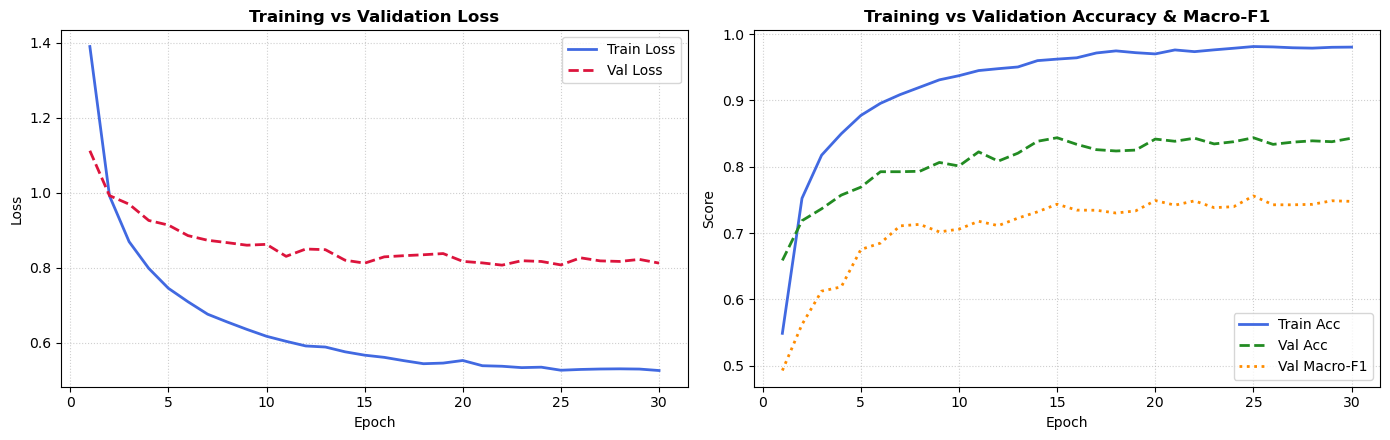

In [6]:
# =========================================================================
# 6. พล็อตกราฟ Loss & Accuracy (วิเคราะห์และตรวจจับ Overfitting)
# =========================================================================
epochs_range = range(1, len(history['train_loss']) + 1)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.5))

# กราฟ Loss (Train vs Val)
ax1.plot(epochs_range, history['train_loss'], label='Train Loss', color='royalblue', lw=2)
ax1.plot(epochs_range, history['val_loss'], label='Val Loss', color='crimson', lw=2, linestyle='--')
ax1.set_title('Training vs Validation Loss', fontsize=12, fontweight='bold')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Loss')
ax1.grid(True, linestyle=':', alpha=0.6)
ax1.legend()

# กราฟ Accuracy และ Macro-F1
ax2.plot(epochs_range, history['train_acc'], label='Train Acc', color='royalblue', lw=2)
ax2.plot(epochs_range, history['val_acc'], label='Val Acc', color='forestgreen', lw=2, linestyle='--')
ax2.plot(epochs_range, history['val_f1'], label='Val Macro-F1', color='darkorange', lw=2, linestyle=':')
ax2.set_title('Training vs Validation Accuracy & Macro-F1', fontsize=12, fontweight='bold')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Score')
ax2.grid(True, linestyle=':', alpha=0.6)
ax2.legend()

plt.tight_layout()
plt.show()

Loading best checkpoint: checkpoints/resnet50_best.pt


Testing Test Set:   0%|          | 0/24 [00:00<?, ?it/s]


CLASSIFICATION REPORT (HELD-OUT TEST SET)
              precision    recall  f1-score   support

       akiec     0.6792    0.7347    0.7059        49
         bcc     0.6848    0.8077    0.7412        78
         bkl     0.7134    0.6788    0.6957       165
          df     0.7059    0.7059    0.7059        17
         mel     0.5680    0.5714    0.5697       168
          nv     0.9197    0.9114    0.9155      1005
        vasc     0.8947    0.8095    0.8500        21

    accuracy                         0.8330      1503
   macro avg     0.7380    0.7456    0.7406      1503
weighted avg     0.8349    0.8330    0.8336      1503



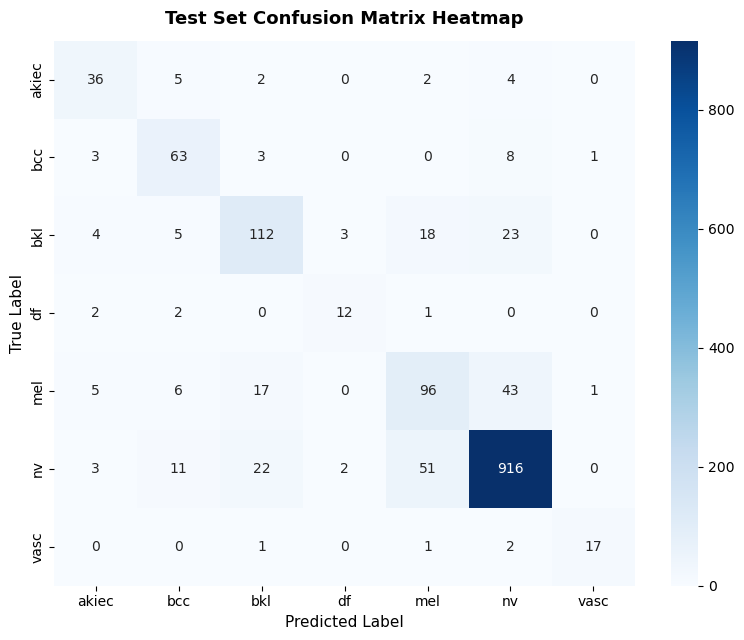

In [7]:
# =========================================================================
# 7. ประเมินผลบน Test Set พร้อม Confusion Matrix Heatmap
# =========================================================================
print(f"Loading best checkpoint: {best_ckpt_path}")
ckpt = torch.load(best_ckpt_path, map_location=device)
model.load_state_dict(ckpt['model_state'])
model.eval()

test_ds = HAM10000Dataset(
    splits_csv=DATA_CONFIG['splits_file'],
    split='test',
    data_dir=DATA_CONFIG['data_dir'],
    transform=val_transform,
)
test_loader = DataLoader(test_ds, batch_size=TRAIN_CONFIG['batch_size'], shuffle=False, num_workers=DATA_CONFIG['num_workers'])

test_preds, test_targets = [], []
with torch.no_grad():
    for imgs, labels in tqdm(test_loader, desc="Testing Test Set", leave=False):
        imgs = imgs.to(device, non_blocking=True)
        with get_amp_context(use_amp=TRAIN_CONFIG['use_amp']):
            outputs = model(imgs)
        test_preds.extend(outputs.argmax(dim=1).cpu().tolist())
        test_targets.extend(labels.tolist())

print('\n' + '=' * 65)
print('CLASSIFICATION REPORT (HELD-OUT TEST SET)')
print('=' * 65)
print(classification_report(test_targets, test_preds, target_names=CLASSES, digits=4))

# พล็อต Confusion Matrix Heatmap
cm = confusion_matrix(test_targets, test_preds)
plt.figure(figsize=(8, 6.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=CLASSES, yticklabels=CLASSES)
plt.title('Test Set Confusion Matrix Heatmap', fontsize=13, fontweight='bold', pad=12)
plt.xlabel('Predicted Label', fontsize=11)
plt.ylabel('True Label', fontsize=11)
plt.tight_layout()
plt.show()
